# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

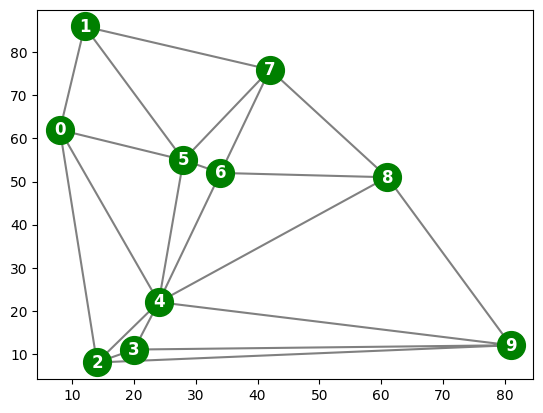

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

In [3]:
# BÀI 1 - KIỂM TRA DANH SÁCH ĐỈNH KỀ

for i in range(n):
    print(f"Đỉnh {i}: {sorted(neighbors[i])}")

Đỉnh 0: [np.int32(1), np.int32(2), np.int32(4), np.int32(5)]
Đỉnh 1: [np.int32(0), np.int32(5), np.int32(7)]
Đỉnh 2: [np.int32(0), np.int32(3), np.int32(4), np.int32(9)]
Đỉnh 3: [np.int32(2), np.int32(4), np.int32(9)]
Đỉnh 4: [np.int32(0), np.int32(2), np.int32(3), np.int32(5), np.int32(6), np.int32(8), np.int32(9)]
Đỉnh 5: [np.int32(0), np.int32(1), np.int32(4), np.int32(6), np.int32(7)]
Đỉnh 6: [np.int32(4), np.int32(5), np.int32(7), np.int32(8)]
Đỉnh 7: [np.int32(1), np.int32(5), np.int32(6), np.int32(8)]
Đỉnh 8: [np.int32(4), np.int32(6), np.int32(7), np.int32(9)]
Đỉnh 9: [np.int32(2), np.int32(3), np.int32(4), np.int32(8)]


## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [4]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

In [5]:
# BÀI 1 - KIỂM TRA MÔ HÌNH CSP

print("Số biến:", len(csp["variables"]))
print("Danh sách biến:", csp["variables"])

print("\nMiền giá trị:")
for var in csp["variables"]:
    print(f"Đỉnh {var}: {csp['domains'][var]}")

print("\nSố ràng buộc:", len(csp["constraints"]))
print("Danh sách ràng buộc:")
for constraint in csp["constraints"]:
    print(constraint)

Số biến: 10
Danh sách biến: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

Miền giá trị:
Đỉnh 0: ['red', 'blue', 'green', 'orange']
Đỉnh 1: ['red', 'blue', 'green', 'orange']
Đỉnh 2: ['red', 'blue', 'green', 'orange']
Đỉnh 3: ['red', 'blue', 'green', 'orange']
Đỉnh 4: ['red', 'blue', 'green', 'orange']
Đỉnh 5: ['red', 'blue', 'green', 'orange']
Đỉnh 6: ['red', 'blue', 'green', 'orange']
Đỉnh 7: ['red', 'blue', 'green', 'orange']
Đỉnh 8: ['red', 'blue', 'green', 'orange']
Đỉnh 9: ['red', 'blue', 'green', 'orange']

Số ràng buộc: 21
Danh sách ràng buộc:
('0', '1')
('0', '2')
('0', '4')
('0', '5')
('1', '5')
('1', '7')
('2', '3')
('2', '4')
('2', '9')
('3', '4')
('3', '9')
('4', '5')
('4', '6')
('4', '8')
('4', '9')
('5', '6')
('5', '7')
('6', '7')
('6', '8')
('7', '8')
('8', '9')


In [6]:
# BÀI 1 - KHẢO SÁT MIỀN 3 MÀU VÀ 4 MÀU

colors_4 = ['red', 'blue', 'green', 'orange']
colors_3 = ['red', 'blue', 'green']

csp_4 = {
    'variables': csp['variables'],
    'domains': {v: colors_4.copy() for v in csp['variables']},
    'constraints': csp['constraints']
}

csp_3 = {
    'variables': csp['variables'],
    'domains': {v: colors_3.copy() for v in csp['variables']},
    'constraints': csp['constraints']
}

print("=== CSP VỚI 4 MÀU ===")
print("Số biến:", len(csp_4['variables']))
print("Số màu mỗi đỉnh:", len(csp_4['domains']['0']))
print("Miền màu:", csp_4['domains']['0'])
print("Số ràng buộc:", len(csp_4['constraints']))

print("\n=== CSP VỚI 3 MÀU ===")
print("Số biến:", len(csp_3['variables']))
print("Số màu mỗi đỉnh:", len(csp_3['domains']['0']))
print("Miền màu:", csp_3['domains']['0'])
print("Số ràng buộc:", len(csp_3['constraints']))

=== CSP VỚI 4 MÀU ===
Số biến: 10
Số màu mỗi đỉnh: 4
Miền màu: ['red', 'blue', 'green', 'orange']
Số ràng buộc: 21

=== CSP VỚI 3 MÀU ===
Số biến: 10
Số màu mỗi đỉnh: 3
Miền màu: ['red', 'blue', 'green']
Số ràng buộc: 21


### Nhận xét Bài 1

Bài toán tô màu đồ thị được biểu diễn dưới dạng CSP gồm:

- **X (Variables):** 10 đỉnh, từ 0 đến 9.
- **D (Domains):** Miền giá trị gồm 4 màu (red, blue, green,
  orange) hoặc 3 màu (red, blue, green).
- **C (Constraints):** Hai đỉnh có cạnh nối trực tiếp phải
  được gán hai màu khác nhau.

Đồ thị có 21 cạnh, tương ứng với 21 ràng buộc.
Chỉ xét các cạnh i < j để tránh lưu trùng ràng buộc,
vì đồ thị vô hướng có cạnh (i, j) tương đương (j, i).

Khi giảm từ 4 màu xuống 3 màu, số phép gán đầy đủ
có thể tạo giảm từ 4^10 = 1.048.576 xuống
3^10 = 59.049. Tuy nhiên, không phải phép gán
đầy đủ nào cũng hợp lệ vì còn phải thỏa mãn
các ràng buộc tô màu.

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [7]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [8]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


In [9]:
# BÀI 2 - KIỂM TRA PHÉP GÁN RỖNG

assignment_empty = {}

print("Phép gán:", assignment_empty)
print("Complete:", complete(assignment_empty, csp))
print("Consistent:", consistent(assignment_empty, csp))

Phép gán: {}
Complete: False
Consistent: True


In [10]:
# BÀI 2 - CA KIỂM THỬ 2: PHÉP GÁN MỘT PHẦN

assignment_partial = {
    '0': 'red',
    '1': 'blue',
    '2': 'green'
}

print("Phép gán:", assignment_partial)
print("Complete:", complete(assignment_partial, csp))
print("Consistent:", consistent(assignment_partial, csp))

Phép gán: {'0': 'red', '1': 'blue', '2': 'green'}
Complete: False
Consistent: True


In [11]:
# BÀI 2 - CA KIỂM THỬ 3:
# PHÉP GÁN ĐẦY ĐỦ NHƯNG VI PHẠM RÀNG BUỘC

assignment_invalid = {
    var: 'red' for var in csp['variables']
}

print("Phép gán:", assignment_invalid)
print("Complete:", complete(assignment_invalid, csp))
print("Consistent:", consistent(assignment_invalid, csp))

Phép gán: {'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}
Complete: True
Consistent: False


In [12]:
# BÀI 2 - CA KIỂM THỬ 4:
# PHÉP GÁN ĐẦY ĐỦ VÀ NHẤT QUÁN

assignment_valid = {
    '0': 'red',
    '1': 'blue',
    '2': 'green',
    '3': 'blue',
    '4': 'orange',
    '5': 'green',
    '6': 'red',
    '7': 'orange',
    '8': 'blue',
    '9': 'red'
}

print("Phép gán:", assignment_valid)
print("Complete:", complete(assignment_valid, csp))
print("Consistent:", consistent(assignment_valid, csp))

Phép gán: {'0': 'red', '1': 'blue', '2': 'green', '3': 'blue', '4': 'orange', '5': 'green', '6': 'red', '7': 'orange', '8': 'blue', '9': 'red'}
Complete: True
Consistent: True


### Nhận xét kết quả kiểm thử

**Bảng kết quả kiểm thử complete() và consistent()**

| Ca kiểm thử | Complete mong đợi | Consistent mong đợi | Kết quả thực tế |
|---|---|---|---|
| 1. Phép gán rỗng | False | True | Khớp |
| 2. Phép gán một phần | False | True | Khớp |
| 3. Gán toàn bộ màu đỏ | True | False | Khớp |
| 4. Phép gán đầy đủ, hợp lệ | True | True | Khớp |

Qua bốn ca kiểm thử, hàm `complete()` xác định liệu tất cả các biến đã được gán giá trị hay chưa, trong khi hàm `consistent()` kiểm tra các ràng buộc giữa những đỉnh đã được gán màu.

Kết quả cho thấy một phép gán đầy đủ chưa chắc là nghiệm hợp lệ của CSP. Cụ thể, khi tất cả 10 đỉnh đều được gán màu đỏ, `complete()` trả về True nhưng `consistent()` trả về False vì các đỉnh kề nhau có cùng màu.

Một nghiệm CSP hợp lệ phải gán đầy đủ các biến bằng những giá trị thuộc miền cho phép và đồng thời thỏa mãn tất cả các ràng buộc.

## Implement Simple Backtracking Search

In [13]:
# TODO: implement variable ordering. Choose variable with the minimum-remaining-values (MRV)
def select_unassigned_var(assignment, csp):
    if(complete(assignment, csp)): return(None)
    
    return(csp['variables'][np.where([not v in assignment.keys() for v in csp['variables']])[0][0]])

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =", 
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 2


In [14]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    # TODO: implement value ordering. Use the least-constraining-value heuristic. 
    # for val in order_domain(assignment, var, csp)
    for val in csp['domains'][var]:
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            
            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)
                
        del assignment[var]
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

## Run Backtracking Search on the Random Problem

In [15]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: total: 0 ns
Wall time: 969 μs


{'0': 'red',
 '1': 'blue',
 '2': 'blue',
 '3': 'red',
 '4': 'green',
 '5': 'orange',
 '6': 'red',
 '7': 'green',
 '8': 'blue',
 '9': 'orange'}

Plot the resulting coloring

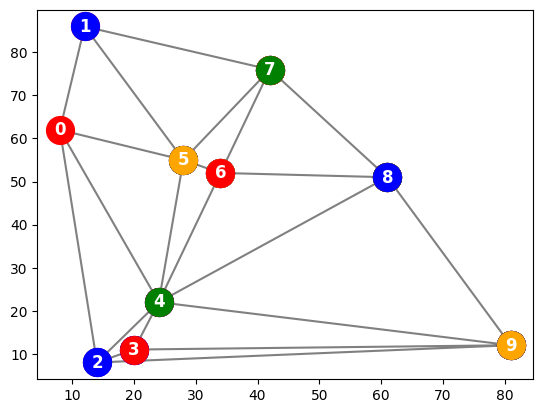

In [16]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

### Bài 3. Backtracking và thứ tự chọn biến

In [17]:
# BÀI 3: BACKTRACKING SEARCH BAN ĐẦU

import time

start = time.perf_counter()
result_bt = backtrack_search(csp_4)
time_bt = time.perf_counter() - start

print("BACKTRACKING SEARCH BAN ĐẦU")
print("Kết quả:", result_bt)
print("Số nút đã kiểm tra:", COUNT)
print(f"Thời gian chạy: {time_bt:.6f} giây")

if result_bt is not None:
    print("Complete:", complete(result_bt, csp_4))
    print("Consistent:", consistent(result_bt, csp_4))

Checked nodes: 11
BACKTRACKING SEARCH BAN ĐẦU
Kết quả: {'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}
Số nút đã kiểm tra: 11
Thời gian chạy: 0.000607 giây
Complete: True
Consistent: True


#### Trực quan hóa kết quả

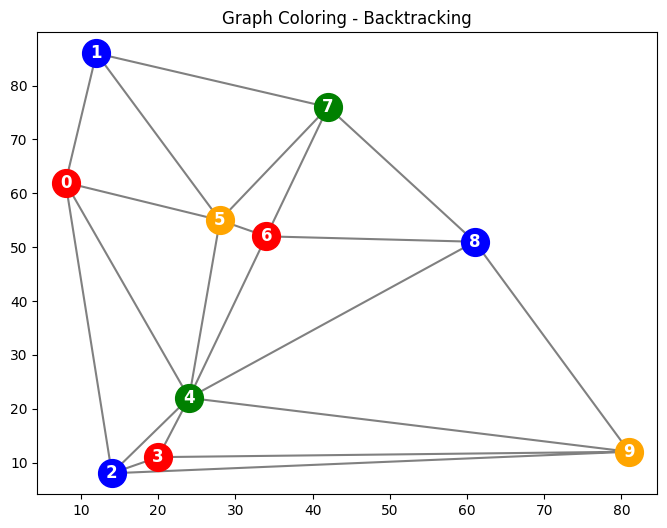

In [18]:
# BÀI 3: VẼ ĐỒ THỊ SAU KHI TÔ MÀU

def draw_coloring(points, tri, assignment, title):
    if assignment is None:
        print("Không có nghiệm để trực quan hóa.")
        return

    plt.figure(figsize=(8, 6))
    plt.triplot(points[:, 0], points[:, 1],
                tri.simplices, color="gray")

    for i in range(len(points)):
        color = assignment[str(i)]

        plt.plot(
            points[i, 0], points[i, 1],
            "o", color=color, markersize=20
        )

        plt.annotate(
            str(i), points[i, :],
            color="white", fontsize="large",
            weight="heavy",
            ha="center", va="center"
        )

    plt.title(title)
    plt.show()


draw_coloring(
    points, tri, result_bt,
    "Graph Coloring - Backtracking"
)

#### Các hàm hỗ trợ MRV và LCV

In [19]:
# BÀI 3: CÁC HÀM HỖ TRỢ MRV VÀ LCV

def get_adjacency(csp):
    adjacency = {v: set() for v in csp["variables"]}

    for u, v in csp["constraints"]:
        adjacency[u].add(v)
        adjacency[v].add(u)

    return adjacency


def get_legal_values(var, assignment, domains, adjacency):
    used_colors = {
        assignment[u]
        for u in adjacency[var]
        if u in assignment
    }

    return [
        color for color in domains[var]
        if color not in used_colors
    ]


def select_var_mrv(assignment, domains, adjacency, csp):
    unassigned = [
        v for v in csp["variables"]
        if v not in assignment
    ]

    if not unassigned:
        return None

    return min(
        unassigned,
        key=lambda v: len(
            get_legal_values(v, assignment, domains, adjacency)
        )
    )


def order_values_lcv(var, assignment, domains, adjacency):
    legal_values = get_legal_values(
        var, assignment, domains, adjacency
    )

    def impact(color):
        count = 0

        for u in adjacency[var]:
            if u not in assignment and color in domains[u]:
                count += 1

        return count

    return sorted(legal_values, key=impact)

#### Backtracking mở rộng

In [20]:
# BÀI 3: BACKTRACKING MỞ RỘNG

def backtracking_advanced(
    csp,
    use_mrv=False,
    use_lcv=False,
    use_fc=False,
    max_nodes=20000
):
    start = time.perf_counter()

    adjacency = get_adjacency(csp)

    domains = {
        v: list(csp["domains"][v])
        for v in csp["variables"]
    }

    stats = {
        "nodes": 0,
        "attempts": 0,
        "cutoff": False
    }

    def backtrack_advanced(assignment, current_domains):

        if stats["nodes"] >= max_nodes:
            stats["cutoff"] = True
            return None

        stats["nodes"] += 1

        if complete(assignment, csp):
            return assignment.copy()

        # Chọn biến
        if use_mrv:
            var = select_var_mrv(
                assignment, current_domains, adjacency, csp
            )
        else:
            var = next(
                v for v in csp["variables"]
                if v not in assignment
            )

        # Sắp xếp thứ tự giá trị
        if use_lcv:
            values = order_values_lcv(
                var, assignment, current_domains, adjacency
            )
        else:
            values = list(current_domains[var])

        for color in values:
            stats["attempts"] += 1
            assignment[var] = color

            if consistent(assignment, csp):

                # Forward Checking
                if use_fc:
                    next_domains = {
                        v: list(current_domains[v])
                        for v in current_domains
                    }

                    valid = True

                    for neighbor in adjacency[var]:
                        if neighbor not in assignment:
                            if color in next_domains[neighbor]:
                                next_domains[neighbor].remove(color)

                            if not next_domains[neighbor]:
                                valid = False
                                break

                    if valid:
                        result = backtrack_advanced(
                            assignment, next_domains
                        )
                    else:
                        result = None

                else:
                    result = backtrack_advanced(
                        assignment, current_domains
                    )

                if result is not None:
                    return result

            del assignment[var]

            if stats["cutoff"]:
                break

        return None

    result = backtrack_advanced({}, domains)

    elapsed = time.perf_counter() - start

    if result is not None:
        status = "Solved"
    elif stats["cutoff"]:
        status = "Cutoff"
    else:
        status = "Unsatisfiable"

    return {
        "solution": result,
        "nodes": stats["nodes"],
        "attempts": stats["attempts"],
        "time": elapsed,
        "status": status
    }

#### So sánh các chiến lược


=== Backtracking ===
Trạng thái: Solved
Số nút: 11
Số phép gán thử: 23
Thời gian: 0.000327 giây
Nghiệm: {'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}

=== MRV ===
Trạng thái: Solved
Số nút: 11
Số phép gán thử: 24
Thời gian: 0.000463 giây
Nghiệm: {'0': 'red', '1': 'blue', '5': 'green', '4': 'blue', '2': 'green', '3': 'red', '9': 'orange', '6': 'red', '7': 'orange', '8': 'green'}

=== MRV + LCV ===
Trạng thái: Solved
Số nút: 11
Số phép gán thử: 10
Thời gian: 0.000330 giây
Nghiệm: {'0': 'red', '1': 'blue', '5': 'green', '4': 'blue', '2': 'green', '3': 'red', '9': 'orange', '6': 'red', '7': 'orange', '8': 'green'}


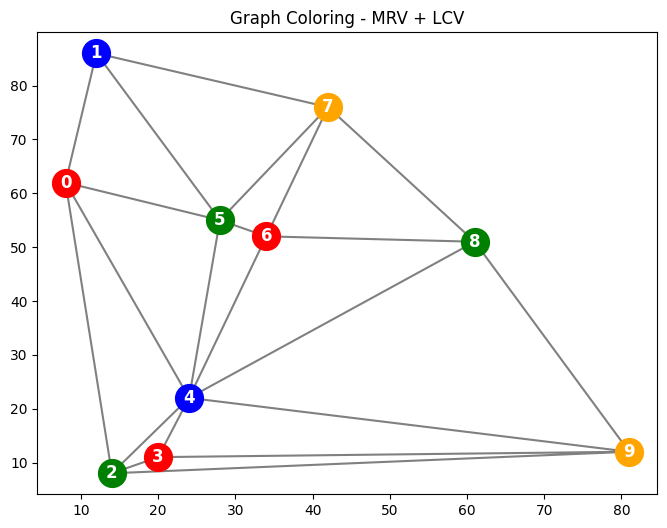

In [21]:
# BÀI 3: SO SÁNH CÁC CHIẾN LƯỢC

algorithms_3 = {
    "Backtracking": (False, False),
    "MRV": (True, False),
    "MRV + LCV": (True, True)
}

results_3 = {}

for name, (mrv, lcv) in algorithms_3.items():

    result = backtracking_advanced(
        csp_4,
        use_mrv=mrv,
        use_lcv=lcv
    )

    results_3[name] = result

    print(f"\n=== {name} ===")
    print("Trạng thái:", result["status"])
    print("Số nút:", result["nodes"])
    print("Số phép gán thử:", result["attempts"])
    print(f"Thời gian: {result['time']:.6f} giây")
    print("Nghiệm:", result["solution"])


# Trực quan hóa nghiệm MRV + LCV
draw_coloring(
    points, tri,
    results_3["MRV + LCV"]["solution"],
    "Graph Coloring - MRV + LCV"
)

### Nhận xét

Trên đồ thị 10 đỉnh với miền 4 màu, cả ba thuật toán Backtracking, MRV và MRV + LCV đều tìm được nghiệm hợp lệ với 11 nút tìm kiếm. Tuy nhiên, số phép gán thử có sự khác biệt: Backtracking cần 23 phép, MRV cần 24 phép, trong khi MRV + LCV chỉ cần 10 phép.

MRV ưu tiên chọn biến có ít giá trị hợp lệ còn lại nhất nhằm phát hiện xung đột sớm. Tuy nhiên, trong trường hợp này, MRV không làm giảm số nút hoặc số phép gán thử so với Backtracking gốc. Khi kết hợp với LCV, số phép gán thử giảm đáng kể nhờ ưu tiên các màu ít hạn chế miền giá trị của các đỉnh chưa gán.

Thời gian chạy của các thuật toán đều rất nhỏ, chỉ khoảng 0,0003–0,0005 giây. Vì vậy, chưa thể kết luận chắc chắn thuật toán nào có hiệu quả thời gian tốt hơn chỉ dựa trên một đồ thị.

Kết quả cho thấy việc sử dụng MRV và LCV có thể cải thiện hiệu quả tìm kiếm, nhưng mức độ cải thiện phụ thuộc vào cấu trúc đồ thị và thứ tự chọn biến, chọn giá trị.

### Bài 4. Forward Checking và Min-Conflicts

=== MRV + LCV + FORWARD CHECKING ===
Trạng thái: Solved
Số nút: 11
Số phép gán thử: 10
Thời gian: 0.000900 giây
Nghiệm: {'0': 'red', '1': 'blue', '5': 'green', '4': 'blue', '2': 'green', '3': 'red', '9': 'orange', '6': 'orange', '7': 'red', '8': 'green'}
Complete: True
Consistent: True


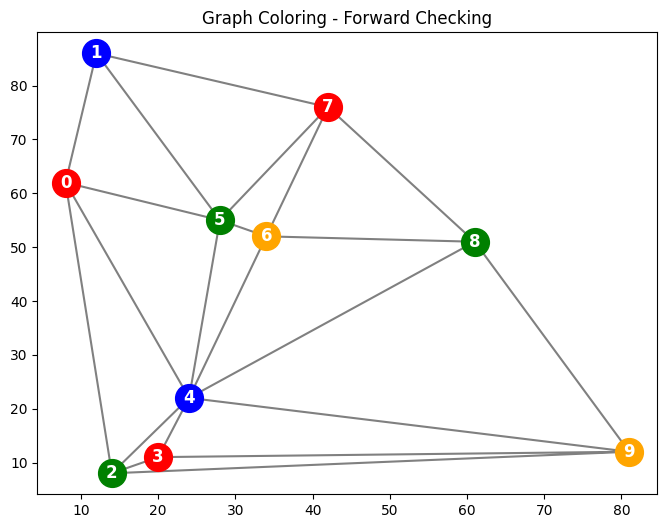

In [22]:
# BÀI 4: FORWARD CHECKING

result_fc = backtracking_advanced(
    csp_4,
    use_mrv=True,
    use_lcv=True,
    use_fc=True
)

print("=== MRV + LCV + FORWARD CHECKING ===")
print("Trạng thái:", result_fc["status"])
print("Số nút:", result_fc["nodes"])
print("Số phép gán thử:", result_fc["attempts"])
print(f"Thời gian: {result_fc['time']:.6f} giây")
print("Nghiệm:", result_fc["solution"])

if result_fc["solution"] is not None:
    print(
        "Complete:",
        complete(result_fc["solution"], csp_4)
    )
    print(
        "Consistent:",
        consistent(result_fc["solution"], csp_4)
    )

draw_coloring(
    points, tri,
    result_fc["solution"],
    "Graph Coloring - Forward Checking"
)

#### Cài đặt Min-Conflicts

In [23]:
# BÀI 4: MIN-CONFLICTS

def count_conflicts(assignment, csp):
    return sum(
        assignment[u] == assignment[v]
        for u, v in csp["constraints"]
    )


def min_conflicts(
    csp,
    max_steps=3000,
    max_restarts=10,
    seed=None
):
    start = time.perf_counter()
    rng = np.random.default_rng(seed)

    adjacency = get_adjacency(csp)
    variables = csp["variables"]

    total_steps = 0
    uphill_moves = 0
    sideways_moves = 0
    best_solution = None
    best_conflicts = float("inf")

    for restart in range(max_restarts + 1):

        # Khởi tạo phép gán đầy đủ ngẫu nhiên
        assignment = {
            v: rng.choice(csp["domains"][v])
            for v in variables
        }

        for step in range(max_steps + 1):

            current_conflicts = count_conflicts(
                assignment, csp
            )

            if current_conflicts < best_conflicts:
                best_conflicts = current_conflicts
                best_solution = assignment.copy()

            if current_conflicts == 0:
                return {
                    "solution": assignment.copy(),
                    "conflicts": 0,
                    "steps": total_steps,
                    "restarts": restart,
                    "uphill_moves": uphill_moves,
                    "sideways_moves": sideways_moves,
                    "time": time.perf_counter() - start,
                    "status": "Solved"
                }

            if step == max_steps:
                break

            # Lấy các đỉnh đang vi phạm ràng buộc
            conflicted_vars = [
                v for v in variables
                if any(
                    assignment[v] == assignment[u]
                    for u in adjacency[v]
                )
            ]

            var = rng.choice(conflicted_vars)

            old_conflicts = current_conflicts

            # Đánh giá các màu có thể gán
            color_scores = {}

            for color in csp["domains"][var]:
                local_conflicts = sum(
                    assignment[u] == color
                    for u in adjacency[var]
                )

                color_scores[color] = local_conflicts

            # Chọn màu có ít xung đột nhất
            min_score = min(color_scores.values())

            best_colors = [
                color for color, score in color_scores.items()
                if score == min_score
            ]

            assignment[var] = rng.choice(best_colors)
            total_steps += 1

            new_conflicts = count_conflicts(
                assignment, csp
            )

            if new_conflicts > old_conflicts:
                uphill_moves += 1
            elif new_conflicts == old_conflicts:
                sideways_moves += 1

    return {
        "solution": best_solution,
        "conflicts": best_conflicts,
        "steps": total_steps,
        "restarts": max_restarts,
        "uphill_moves": uphill_moves,
        "sideways_moves": sideways_moves,
        "time": time.perf_counter() - start,
        "status": "Not solved"
    }

#### Kiểm thử Min-Conflicts với 3 và 4 màu


=== MIN-CONFLICTS: 3 MÀU ===
Trạng thái: Not solved
Số xung đột tốt nhất: 2
Số bước: 33000
Random Restarts: 10
Uphill Moves: 0
Sideways Moves: 32958
Thời gian: 2.216012 giây

=== MIN-CONFLICTS: 4 MÀU ===
Trạng thái: Solved
Số xung đột tốt nhất: 0
Số bước: 9
Random Restarts: 0
Uphill Moves: 0
Sideways Moves: 4
Thời gian: 0.001670 giây
Complete: True
Consistent: True


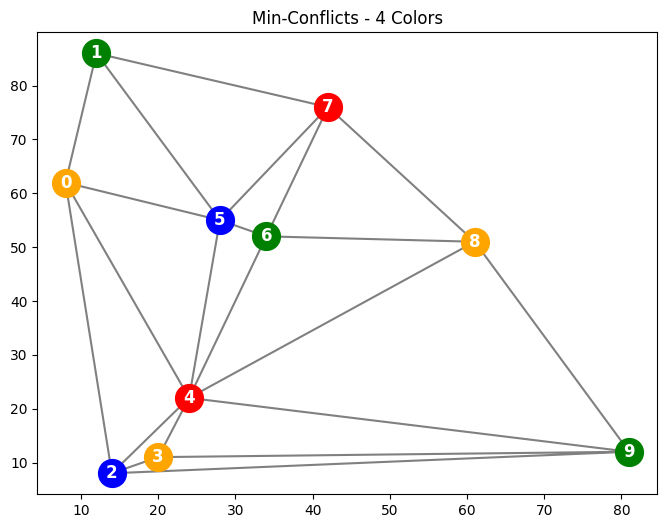

In [24]:
# BÀI 4: KIỂM THỬ MIN-CONFLICTS

for num_colors, problem in [(3, csp_3), (4, csp_4)]:

    result = min_conflicts(
        problem,
        max_steps=3000,
        max_restarts=10,
        seed=1111
    )

    print(f"\n=== MIN-CONFLICTS: {num_colors} MÀU ===")
    print("Trạng thái:", result["status"])
    print("Số xung đột tốt nhất:", result["conflicts"])
    print("Số bước:", result["steps"])
    print("Random Restarts:", result["restarts"])
    print("Uphill Moves:", result["uphill_moves"])
    print("Sideways Moves:", result["sideways_moves"])
    print(f"Thời gian: {result['time']:.6f} giây")

    if result["status"] == "Solved":
        print("Complete:", complete(result["solution"], problem))
        print("Consistent:", consistent(result["solution"], problem))

        draw_coloring(
            points, tri,
            result["solution"],
            f"Min-Conflicts - {num_colors} Colors"
        )

#### Thực nghiệm nhiều kích thước đồ thị với 3 và 4 màu

Để đánh giá hiệu quả thuật toán, thực nghiệm được thực hiện trên các đồ thị ngẫu nhiên có số đỉnh n = 10, 15, 20 và miền gồm 3 hoặc 4 màu.

Mỗi cấu hình được kiểm thử với 5 seed khác nhau. Các thuật toán sử dụng cùng tập đồ thị tại mỗi cấu hình nhằm bảo đảm tính công bằng khi so sánh.

Các tiêu chí đánh giá gồm tỷ lệ tìm được nghiệm, số nút tìm kiếm hoặc số bước, thời gian chạy và số cạnh trung bình.

In [26]:
# BÀI 4: SINH ĐỒ THỊ VÀ CHẠY THỰC NGHIỆM

import pandas as pd

def generate_csp(n, num_colors, seed):
    rng = np.random.default_rng(seed)

    points_new = rng.random((n, 2)) * 100
    tri_new = Delaunay(points_new)

    indptr, indices = tri_new.vertex_neighbor_vertices

    neighbors_new = [
        np.sort(indices[indptr[i]:indptr[i + 1]])
        for i in range(n)
    ]

    variables_new = [str(i) for i in range(n)]

    colors = ["red", "blue", "green", "orange"][:num_colors]

    constraints_new = set()

    for i in range(n):
        for j in neighbors_new[i]:
            if i < j:
                constraints_new.add((str(i), str(j)))

    return {
        "variables": variables_new,
        "domains": {
            v: colors.copy() for v in variables_new
        },
        "constraints": constraints_new
    }


# Các thuật toán cần so sánh
configs = {
    "Backtracking": (False, False, False),
    "MRV": (True, False, False),
    "MRV + LCV": (True, True, False),
    "Forward Checking": (True, True, True)
}

records = []

n_values = [10, 15, 20]
seeds = [1111, 2222, 3333, 4444, 5555]

for n in n_values:
    for num_colors in [3, 4]:
        for seed in seeds:

            problem = generate_csp(n, num_colors, seed)
            edges = len(problem["constraints"])

            for name, (mrv, lcv, fc) in configs.items():

                result = backtracking_advanced(
                    problem,
                    use_mrv=mrv,
                    use_lcv=lcv,
                    use_fc=fc,
                    max_nodes=20000
                )

                solution = result["solution"]

                success = (
                    solution is not None
                    and complete(solution, problem)
                    and consistent(solution, problem)
                )

                records.append({
                    "n": n,
                    "colors": num_colors,
                    "seed": seed,
                    "edges": edges,
                    "algorithm": name,
                    "success": int(success),
                    "nodes": result["nodes"],
                    "attempts": result["attempts"],
                    "time": result["time"],
                    "status": result["status"]
                    
                })

            # Min-Conflicts
            result = min_conflicts(
                problem,
                max_steps=300 * n,
                max_restarts=10,
                seed=seed
            )

            success = (
                result["status"] == "Solved"
                and complete(result["solution"], problem)
                and consistent(result["solution"], problem)
            )

            records.append({
                "uphill_moves": result["uphill_moves"],
                "restarts": result["restarts"],
                "sideways_moves": result["sideways_moves"],
                "n": n,
                "colors": num_colors,
                "seed": seed,
                "edges": edges,
                "algorithm": "Min-Conflicts",
                "success": int(success),
                "nodes": np.nan,
                "attempts": result["steps"],
                "time": result["time"],
                "status": result["status"]
            })

df = pd.DataFrame(records)

print("Đã hoàn thành thực nghiệm.")
print("Tổng số lượt chạy:", len(df))
display(df.head(10))

Đã hoàn thành thực nghiệm.
Tổng số lượt chạy: 150


,n,colors,seed,edges,algorithm,success,nodes,attempts,time,status,uphill_moves,restarts,sideways_moves
0,10,3,1111,20,Backtracking,0,523.0,1569,0.010716,Unsatisfiable,NaN,NaN,NaN
1,10,3,1111,20,MRV,0,34.0,102,0.001118,Unsatisfiable,NaN,NaN,NaN
2,10,3,1111,20,MRV + LCV,0,34.0,33,0.000809,Unsatisfiable,NaN,NaN,NaN
3,10,3,1111,20,Forward Checking,0,28.0,33,0.000640,Unsatisfiable,NaN,NaN,NaN
4,10,3,1111,20,Min-Conflicts,0,NaN,33000,2.177039,Not solved,0.0,10.0,32951.0
5,10,3,2222,20,Backtracking,0,124.0,372,0.002436,Unsatisfiable,NaN,NaN,NaN
6,10,3,2222,20,MRV,0,28.0,84,0.000794,Unsatisfiable,NaN,NaN,NaN
7,10,3,2222,20,MRV + LCV,0,28.0,27,0.000782,Unsatisfiable,NaN,NaN,NaN
8,10,3,2222,20,Forward Checking,0,22.0,27,0.000761,Unsatisfiable,NaN,NaN,NaN
9,10,3,2222,20,Min-Conflicts,0,NaN,33000,2.258654,Not solved,0.0,10.0,32961.0


#### Tổng hợp kết quả thực nghiệm

In [27]:
# BÀI 4: BẢNG TỔNG HỢP

summary = (
    df.groupby(["n", "colors", "algorithm"])
    .agg(
        avg_edges=("edges", "mean"),
        success_rate=("success", "mean"),
        avg_nodes=("nodes", "mean"),
        avg_attempts=("attempts", "mean"),
        avg_time=("time", "mean")
    )
    .reset_index()
)

summary["success_rate"] *= 100

print("Bảng kết quả thực nghiệm")

display(summary.round(4))


print("\nSố lượt theo trạng thái")

display(
    df.groupby(
        ["n", "colors", "algorithm", "status"]
    ).size().unstack(fill_value=0)
)

Bảng kết quả thực nghiệm


,n,colors,algorithm,avg_edges,success_rate,avg_nodes,avg_attempts,avg_time
0,10,3,Backtracking,21.0,20.0,179.2,535.2,0.0037
1,10,3,Forward Checking,21.0,20.0,25.8,29.6,0.0007
2,10,3,MRV,21.0,20.0,30.6,89.2,0.0009
3,10,3,MRV + LCV,21.0,20.0,30.6,29.6,0.0008
4,10,3,Min-Conflicts,21.0,20.0,NaN,26403.2,1.7657
5,10,4,Backtracking,21.0,100.0,11.0,23.4,0.0002
6,10,4,Forward Checking,21.0,100.0,11.0,10.0,0.0003
7,10,4,MRV,21.0,100.0,11.0,21.0,0.0003
8,10,4,MRV + LCV,21.0,100.0,11.0,10.0,0.0003
9,10,4,Min-Conflicts,21.0,100.0,NaN,12.6,0.0014



Số lượt theo trạng thái


status                      Not solved  Solved  Unsatisfiable
n  colors algorithm                                          
10 3      Backtracking               0       1              4
          Forward Checking           0       1              4
          MRV                        0       1              4
          MRV + LCV                  0       1              4
          Min-Conflicts              4       1              0
   4      Backtracking               0       5              0
          Forward Checking           0       5              0
          MRV                        0       5              0
          MRV + LCV                  0       5              0
          Min-Conflicts              0       5              0
15 3      Backtracking               0       0              5
          Forward Checking           0       0              5
          MRV                        0       0              5
          MRV + LCV                  0       0              5
          Min-Conflicts              5       0              0
   4      Backtracking               0       5              0
          Forward Checking           0       5              0
          MRV                        0       5              0
          MRV + LCV                  0       5              0
          Min-Conflicts              0       5              0
20 3      Backtracking               0       0              5
          Forward Checking           0       0              5
          MRV                        0       0              5
          MRV + LCV                  0       0              5
          Min-Conflicts              5       0              0
   4      Backtracking               0       5              0
          Forward Checking           0       5              0
          MRV                        0       5              0
          MRV + LCV                  0       5              0
          Min-Conflicts              0       5              0

In [28]:
# THỐNG KÊ RIÊNG MIN-CONFLICTS

mc_summary = (
    df[df["algorithm"] == "Min-Conflicts"]
    .groupby(["n", "colors"])
    .agg(
        success_rate=("success", "mean"),
        avg_steps=("attempts", "mean"),
        avg_uphill=("uphill_moves", "mean"),
        avg_sideways=("sideways_moves", "mean"),
        avg_restarts=("restarts", "mean"),
        avg_time=("time", "mean")
    )
    .reset_index()
)

mc_summary["success_rate"] *= 100

display(mc_summary.round(4))

,n,colors,success_rate,avg_steps,avg_uphill,avg_sideways,avg_restarts,avg_time
0,10,3,20.0,26403.2,0.0,26368.0,8.0,1.7657
1,10,4,100.0,12.6,0.0,9.4,0.0,0.0014
2,15,3,0.0,49500.0,0.0,49423.2,10.0,4.0297
3,15,4,100.0,30.0,0.0,22.8,0.0,0.0036
4,20,3,0.0,66000.0,0.0,65901.8,10.0,6.6144
5,20,4,100.0,35.2,0.0,24.6,0.0,0.0050


In [31]:
# Thống kê Random Restart khi tìm được nghiệm

mc_success = df[
    (df["algorithm"] == "Min-Conflicts")
    & (df["success"] == 1)
]

restart_success = (
    mc_success.groupby(["n", "colors"])
    .agg(
        successful_runs=("success", "sum"),
        avg_restarts_to_solution=("restarts", "mean")
    )
    .reset_index()
)

display(restart_success.round(4))

,n,colors,successful_runs,avg_restarts_to_solution
0,10,3,1,0.0
1,10,4,5,0.0
2,15,4,5,0.0
3,20,4,5,0.0


Bảng chỉ thống kê số lần Random Restart của các lượt tìm được nghiệm. Những cấu hình không có lượt thành công sẽ không xuất hiện trong bảng. Trong các lượt thành công của thực nghiệm, Min-Conflicts đều tìm được nghiệm ngay từ trạng thái khởi tạo đầu tiên mà không cần Random Restart.

#### Biểu đồ so sánh tỷ lệ thành công

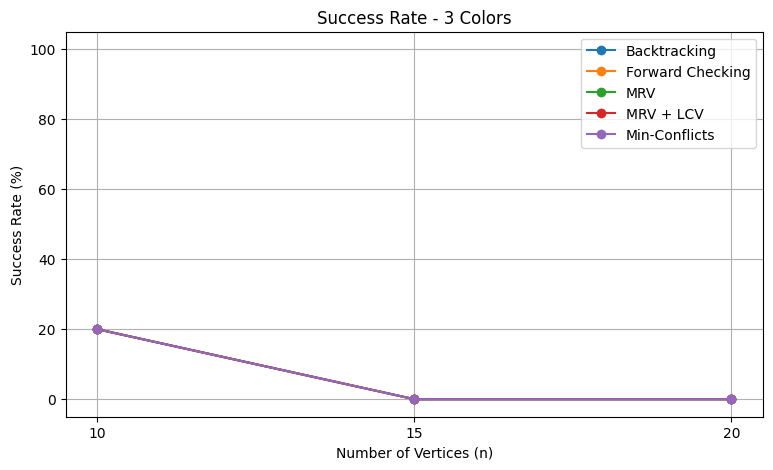

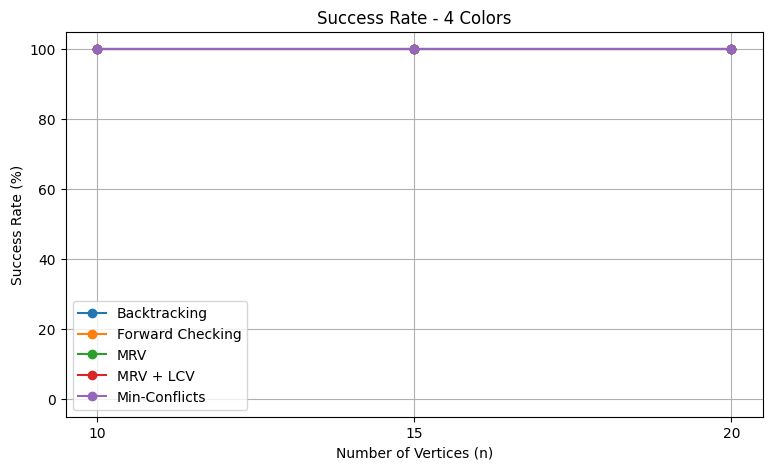

In [29]:
# BÀI 4: BIỂU ĐỒ TỶ LỆ THÀNH CÔNG

for num_colors in [3, 4]:

    data = summary[summary["colors"] == num_colors]

    plt.figure(figsize=(9, 5))

    for name in data["algorithm"].unique():
        subset = data[data["algorithm"] == name]

        plt.plot(
            subset["n"],
            subset["success_rate"],
            marker="o",
            label=name
        )

    plt.title(f"Success Rate - {num_colors} Colors")
    plt.xlabel("Number of Vertices (n)")
    plt.ylabel("Success Rate (%)")
    plt.ylim(-5, 105)
    plt.xticks(n_values)
    plt.legend()
    plt.grid(True)
    plt.show()

#### Biểu đồ so sánh thời gian chạy

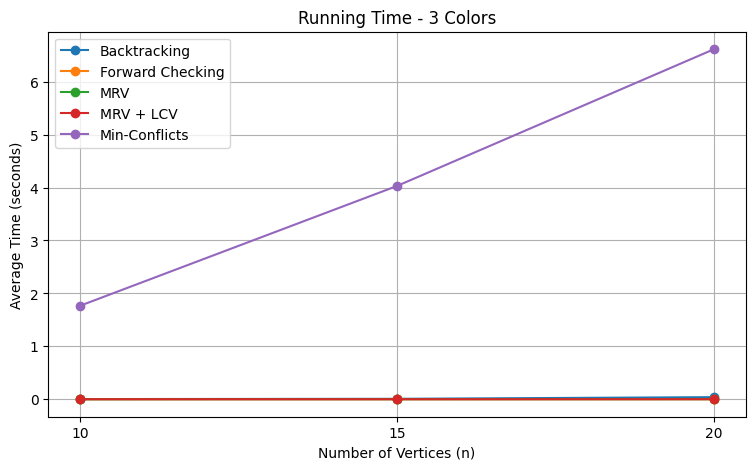

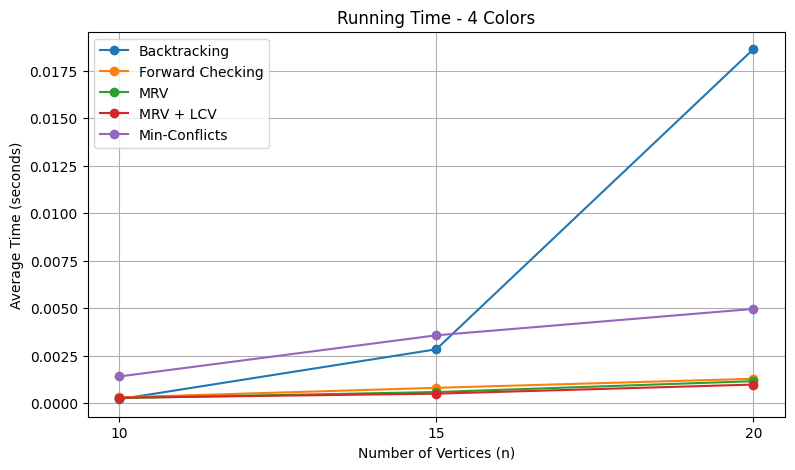

In [30]:
# BÀI 4: BIỂU ĐỒ THỜI GIAN CHẠY

for num_colors in [3, 4]:

    data = summary[summary["colors"] == num_colors]

    plt.figure(figsize=(9, 5))

    for name in data["algorithm"].unique():
        subset = data[data["algorithm"] == name]

        plt.plot(
            subset["n"],
            subset["avg_time"],
            marker="o",
            label=name
        )

    plt.title(f"Running Time - {num_colors} Colors")
    plt.xlabel("Number of Vertices (n)")
    plt.ylabel("Average Time (seconds)")
    plt.xticks(n_values)
    plt.legend()
    plt.grid(True)
    plt.show()

### Nhận xét Bài 4

Thực nghiệm được thực hiện trên các đồ thị ngẫu nhiên có 10, 15 và 20 đỉnh, với miền 3 và 4 màu. Mỗi cấu hình sử dụng 5 seed, tổng cộng có 150 lượt chạy trên 5 thuật toán. Số cạnh trung bình tương ứng với n = 10, 15 và 20 lần lượt là 21, 36 và 50,4 cạnh.

Về tỷ lệ thành công: Với miền 4 màu, tất cả thuật toán đều đạt tỷ lệ thành công 100%. Với miền 3 màu, tỷ lệ thành công là 20% khi n = 10 và 0% khi n = 15 hoặc n = 20. Kết quả Backtracking xác nhận rằng 14/15 đồ thị thử nghiệm không tồn tại nghiệm tô màu hợp lệ bằng 3 màu.

Về hiệu quả Backtracking và Forward Checking: Khi n = 20 với miền 4 màu, Backtracking gốc cần trung bình 1.240,2 phép gán thử, MRV cần 48,2 phép, trong khi MRV + LCV và Forward Checking chỉ cần 20 phép. Forward Checking giúp phát hiện sớm các miền giá trị rỗng, từ đó giảm số nhánh tìm kiếm không cần thiết. Tuy nhiên, việc kiểm tra và cập nhật miền cũng phát sinh thêm chi phí tính toán.

Về Min-Conflicts: Với miền 4 màu, thuật toán đạt tỷ lệ thành công 100%, số bước trung bình tăng từ 12,6 khi n = 10 lên 35,2 khi n = 20. Các trường hợp này không cần khởi động lại. Ngược lại, với miền 3 màu, thuật toán thường không tìm được nghiệm trong giới hạn cho phép và sử dụng gần hết ngân sách tìm kiếm.

Số uphill moves luôn bằng 0 vì thuật toán chỉ chọn màu có số xung đột cục bộ nhỏ nhất, kể cả màu hiện tại. Tuy nhiên, thuật toán có thể thực hiện nhiều sideways moves khi số xung đột không thay đổi. Chẳng hạn, với n = 20 và miền 3 màu, số sideways moves trung bình là 65.901,8 trên tổng 66.000 bước. Điều này cho thấy thuật toán dành nhiều bước di chuyển trên các trạng thái không cải thiện hàm mục tiêu.

Kết luận: MRV, LCV và Forward Checking có thể giảm đáng kể số phép gán thử so với Backtracking gốc. Min-Conflicts tìm nghiệm hiệu quả trên các đồ thị 4 màu trong thực nghiệm, nhưng không có khả năng chứng minh vô nghiệm. Backtracking phù hợp khi cần tìm nghiệm hoặc xác định bài toán vô nghiệm, còn Min-Conflicts là phương pháp tìm kiếm cục bộ phụ thuộc vào trạng thái khởi tạo và giới hạn tính toán.